#ASSIGNMENT 2 - DATA MINING
##HUDA SHAHAT 23I-5057

#import the required libraries

In [5]:

import requests
from bs4 import BeautifulSoup
import pandas as pd
from urllib.parse import urljoin
from decimal import Decimal

#inspect the website first page

In [6]:

url = "https://books.toscrape.com/"
response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

books = []

for book in soup.select("article.product_pod"):
    title = book.select_one("h3 a")["title"]

    price_text = book.select_one("p.price_color").get_text(strip=True)
    price = float(
        price_text.replace("£", "").replace("Â", "")
    )

    rating_element = book.select_one("p.star-rating")
    rating_word = next(
        word for word in rating_element["class"]
        if word in rating_map
    )
    rating = rating_map[rating_word]

    availability = book.select_one(
        "p.instock.availability"
    ).get_text(" ", strip=True)

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

print("Number of books scraped:", len(books))
print(books[:3])


Number of books scraped: 20
[{'Title': 'A Light in the Attic', 'Price': 51.77, 'Rating': 3, 'Availability': 'In stock'}, {'Title': 'Tipping the Velvet', 'Price': 53.74, 'Rating': 1, 'Availability': 'In stock'}, {'Title': 'Soumission', 'Price': 50.1, 'Rating': 1, 'Availability': 'In stock'}]


#scrape 3 pages

In [7]:

rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

books = []
base_url = "https://books.toscrape.com/"

for page_number in range(1, 4):
    if page_number == 1:
        url = base_url
    else:
        url = urljoin(
            base_url, f"catalogue/page-{page_number}.html"
        )

    response = requests.get(url, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")

    for book in soup.select("article.product_pod"):
        title = book.select_one("h3 a")["title"]

        price_text = book.select_one(
            "p.price_color"
        ).get_text(strip=True)
        price = float(
            price_text.replace("£", "").replace("Â", "")
        )

        rating_element = book.select_one("p.star-rating")
        rating_word = next(
            word for word in rating_element["class"]
            if word in rating_map
        )
        rating = rating_map[rating_word]

        availability = book.select_one(
            "p.instock.availability"
        ).get_text(" ", strip=True)

        product_link = urljoin(
            url, book.select_one("h3 a")["href"]
        )

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "URL": product_link
        })

df = pd.DataFrame(books)

print("Total books scraped:", len(df))
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Total books scraped: 60


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...



Column names:
['Title', 'Price', 'Rating', 'Availability', 'URL']


#clean and save dataset

In [8]:

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Remove duplicate records, if any
df = df.drop_duplicates(subset="Title").reset_index(drop=True)

# Make sure numeric columns have the correct data types
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

# Save the scraped dataset
df.to_csv("competitor_books.csv", index=False)

print("\nDataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nCSV saved successfully!")


Missing values:
Title           0
Price           0
Rating          0
Availability    0
URL             0
dtype: int64

Dataset shape: (60, 5)

Data types:
Title            object
Price           float64
Rating            int64
Availability     object
URL              object
dtype: object

CSV saved successfully!


#download csv

In [9]:

from google.colab import files
files.download("competitor_books.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#intelligence analysis

In [10]:

# 1. Most expensive book
most_expensive = df.loc[df["Price"].idxmax()]

print("1. Most expensive book:")
print(most_expensive["Title"], "- £", round(most_expensive["Price"], 2))

# 2. Cheapest book
cheapest = df.loc[df["Price"].idxmin()]

print("\n2. Cheapest book:")
print(cheapest["Title"], "- £", round(cheapest["Price"], 2))

# 3. Average price
average_price = df["Price"].mean()

print("\n3. Average book price: £", round(average_price, 2))

# 4. Number of 5-star books
five_star_books = df[df["Rating"] == 5]

print("\n4. Number of 5-star books:", len(five_star_books))

# 5. Percentage of books in stock
in_stock = df["Availability"].str.contains(
    "in stock", case=False, na=False
)

stock_percentage = in_stock.mean() * 100

print("\n5. Percentage in stock:", round(stock_percentage, 2), "%")

# 6. Top 5 highest-rated books
top_five = df.sort_values(
    by=["Rating", "Price"],
    ascending=[False, True]
).head(5)

print("\n6. Top 5 highest-rated books:")
display(top_five[["Title", "Price", "Rating"]])

# 7. Cheapest book among 5-star books
if not five_star_books.empty:
    cheapest_five_star = five_star_books.loc[
        five_star_books["Price"].idxmin()
    ]

    print("\n7. Cheapest 5-star book:")
    print(
        cheapest_five_star["Title"],
        "- £", round(cheapest_five_star["Price"], 2)
    )
else:
    print("\n7. No 5-star books were found in this dataset.")


1. Most expensive book:
Slow States of Collapse: Poems - £ 57.31

2. Cheapest book:
In Her Wake - £ 12.84

3. Average book price: £ 35.0

4. Number of 5-star books: 14

5. Percentage in stock: 100.0 %

6. Top 5 highest-rated books:


,Title,Price,Rating
34,Sophie's World,15.94,5
54,Thirst,17.27,5
12,Set Me Free,17.46,5
30,The Four Agreements: A Practical Guide to Pers...,17.66,5
43,#HigherSelfie: Wake Up Your Life. Free Your So...,23.11,5



7. Cheapest 5-star book:
Sophie's World - £ 15.94


#bonus

Number of books at each rating:
Rating
1    15
2     8
3    13
4    10
5    14
Name: count, dtype: int64


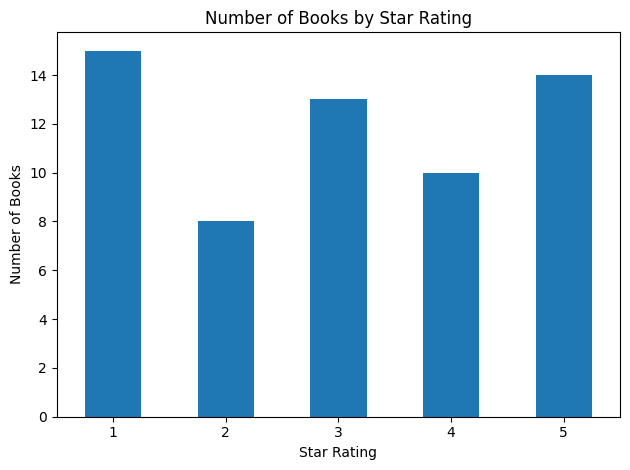

In [11]:

import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()

print("Number of books at each rating:")
print(rating_counts)

rating_counts.plot(kind="bar")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#Complete the £100 CEO Challenge
The goal is to select books with a combined price of no more than £100 while maximizing the sum of their star ratings. This is a small version of the knapsack optimization problem.

For example, a 5-star book contributes 5 points to your total rating score, while a 3-star book contributes 3 points. We want the best combination we can afford, not simply the most expensive books.

In [12]:

# Convert prices into pennies to avoid decimal rounding issues
budget = 10000  # £100 = 10,000 pennies

items = df.dropna(subset=["Price", "Rating"]).copy()
items = items[
    (items["Price"] > 0) &
    (items["Rating"].between(1, 5))
].reset_index(drop=True)

items["CostPennies"] = (
    items["Price"].mul(100).round().astype(int)
)

# dp[b] stores (total_rating_score, selected_book_indices)
# for an exact spend of b pennies.
dp = [None] * (budget + 1)
dp[0] = (0, ())

# Dynamic programming: consider each book only once
for i, item in items.iterrows():
    cost = int(item["CostPennies"])
    rating = int(item["Rating"])

    if cost > budget:
        continue

    for b in range(budget, cost - 1, -1):
        previous = dp[b - cost]

        if previous is None:
            continue

        candidate = (
            previous[0] + rating,
            previous[1] + (i,)
        )

        if dp[b] is None or candidate[0] > dp[b][0]:
            dp[b] = candidate

# Choose the highest score, preferring lower spending in a tie
best_spend = max(
    range(budget + 1),
    key=lambda b: (
        -1 if dp[b] is None else dp[b][0],
        -b
    )
)

selected_indices = dp[best_spend][1]
selected_books = items.iloc[list(selected_indices)].copy()

print("Selected books:")
display(selected_books[["Title", "Price", "Rating"]])

total_cost = selected_books["Price"].sum()
total_rating = selected_books["Rating"].sum()

print("Total cost: £", round(total_cost, 2))
print("Total rating score:", int(total_rating))
print("Remaining budget: £", round(100 - total_cost, 2))


Selected books:


,Title,Price,Rating
10,"Starving Hearts (Triangular Trade Trilogy, #1)",13.99,2
12,Set Me Free,17.46,5
30,The Four Agreements: A Practical Guide to Pers...,17.66,5
34,Sophie's World,15.94,5
47,Untitled Collection: Sabbath Poems 2014,14.27,4
54,Thirst,17.27,5


Total cost: £ 96.59
Total rating score: 26
Remaining budget: £ 3.41


#Business Decision (recomendations)

In [13]:

# Identify highly rated, relatively affordable books
recommended = df[
    (df["Rating"] >= 4) &
    (df["Availability"].str.contains(
        "in stock", case=False, na=False
    ))
].sort_values(
    ["Rating", "Price"],
    ascending=[False, True]
)

print("Recommended books to prioritize:")
display(recommended[["Title", "Price", "Rating"]].head(5))

# Evidence from the scraped data
print("\nEvidence for the business decision:")
print("Average price: £", round(df["Price"].mean(), 2))
print("Average rating:", round(df["Rating"].mean(), 2), "/ 5")
print("Number of 4- and 5-star books:", int((df["Rating"] >= 4).sum()))
print("Number of books in stock:", int(
    df["Availability"].str.contains(
        "in stock", case=False, na=False
    ).sum()
))


Recommended books to prioritize:


,Title,Price,Rating
34,Sophie's World,15.94,5
54,Thirst,17.27,5
12,Set Me Free,17.46,5
30,The Four Agreements: A Practical Guide to Pers...,17.66,5
43,#HigherSelfie: Wake Up Your Life. Free Your So...,23.11,5



Evidence for the business decision:
Average price: £ 35.0
Average rating: 3.0 / 5
Number of 4- and 5-star books: 24
Number of books in stock: 60


I would prioritize books with high ratings and affordable prices because they can attract customers while keeping purchasing costs manageable. My scraped data shows that the average book price is £35 and that 24 books have ratings of 4 or 5 stars. I would focus on highly rated books that are also in stock, while using the price and rating data to select the most suitable products.